# Indic Med-VQA: layer-wise diagnosis and band-targeted recovery

**Runtime → Change runtime type → L4** (A100 also works; T4/V100 do not — Gemma 3 needs bf16).

How to use this notebook:
- **After any restart or disconnect, run cells 0, 1 and 2 first**, then continue at the step you were on.
- Every cell is safe to rerun: finished work (data, translations, predictions, caches, adapters) is detected on Drive and skipped.
- To pick up a new version of this notebook: **File → Open notebook → GitHub → `sayantansikdar/indic-medvqa-xling`**. Code-only updates arrive by rerunning cell 1.

## 0. GPU, Drive and paths

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
import os, json
import pandas as pd
from IPython.display import Image, display
from google.colab import drive
drive.mount('/content/drive')
R = '/content/drive/MyDrive/xling/runs'      # all outputs (data, caches, adapters, reports)
D = f'{R}/data'
T = f'{R}/medgemma/arogyabodha/test/base'    # Phase A cache, test split
C = f'{R}/medgemma/arogyabodha/calib/base'   # Phase A cache, calib split
TR = f'{R}/train'                            # adapters
PY = '/content/it2env/bin/python'            # translation-only environment (cell 4)
REPO = '/content/indic-medvqa-xling'
MT = 'hi-mt,bn-mt,ta-mt,te-mt'; X = 'MedXpertQA_MM_test'
os.environ['XLING_RUNS'] = R
os.makedirs(D, exist_ok=True)

name, memory.total [MiB]
NVIDIA L4, 23034 MiB
Mounted at /content/drive


## 1. Code and dependencies (also: rerun to pull code updates) — expect `20 passed`

In [2]:
if not os.path.exists(REPO):
    !git clone -q https://github.com/sayantansikdar/indic-medvqa-xling.git {REPO}
%cd {REPO}
!git pull -q
!pip install -q -r requirements.txt
!python -m pytest -q tests 2>&1 | tail -1

/content/indic-medvqa-xling
20 passed in 20.38s


## 2. Hugging Face login
Needs a read token from an account that has accepted the terms for
[MedGemma 1.5 4B](https://huggingface.co/google/medgemma-1.5-4b-it),
[IndicTrans2 en→indic](https://huggingface.co/ai4bharat/indictrans2-en-indic-1B) and
[IndicTrans2 indic→en](https://huggingface.co/ai4bharat/indictrans2-indic-en-1B).

In [3]:
from huggingface_hub import login
login()

## 3. Data (≈ 30–40 min the first time; skipped once built)
Items present in EN + HI + BN + TA + TE with one image and the same answer key; split by image hash (test/calib/train 50/20/30).

In [ ]:
if not os.path.exists(f'{D}/arogyabodha.jsonl'):
    !python -m xling.data arogyabodha --out {D}
if not os.path.exists(f'{D}/vqarad.jsonl'):
    !python -m xling.data vqarad --out {D}
L = ['hi', 'bn', 'ta', 'te']
items = [json.loads(l) for l in open(f'{D}/arogyabodha.jsonl')]
test = [i for i in items if i['split'] == 'test']
print(len(items), 'items; splits:', {s: sum(i['split'] == s for i in items) for s in ['test', 'calib', 'train']})
print('mt :', {l: sum(f'{l}-mt' in i['text'] for i in items) for l in L})
print('tt :', {l: sum(f'{l}-tt' in i['text'] for i in test) for l in L}, 'of', len(test), 'test items')

## 4. Translation with IndicTrans2 (≈ 1–2 h the first time; skipped once done)
`*-mt`: IndicTrans2 from the English source (main Indic condition). `*-tt`: translate-test baseline B1 (test split).
Runs in a separate environment (Python 3.12, torch 2.7.1, transformers 4.53.3) because IndicTrans2's code does not work with transformers 5.
Expect `ENV_OK 2.7.1+cu126 True 4.53.3` first.

In [ ]:
%cd {REPO}
ok = !{PY} -c "import torch, transformers, IndicTransToolkit.processor; print('ENV_OK', torch.__version__, torch.cuda.is_available(), transformers.__version__)" 2>/dev/null
if not any(l.startswith('ENV_OK') for l in ok):
    !uv --version >/dev/null 2>&1 || pip install -q uv
    !rm -rf /content/it2env
    !uv venv -q --python 3.12 /content/it2env
    !uv pip install -q --python {PY} torch==2.7.1 -r requirements-translate.txt
    ok = !{PY} -c "import torch, transformers, IndicTransToolkit.processor; print('ENV_OK', torch.__version__, torch.cuda.is_available(), transformers.__version__)"
print('\n'.join(ok))
assert any(l.startswith('ENV_OK') for l in ok), "translation environment is broken - send the output above"
!{PY} -m xling.translate forward  --items {D}/arogyabodha.jsonl
!{PY} -m xling.translate backward --items {D}/arogyabodha.jsonl --from-variant mt --split test
!{PY} -m xling.translate forward  --items {D}/vqarad.jsonl

## 5. Phase A — zero-shot baseline (B0) + residual / lens / attention cache (≈ 2.5–3 h; skipped once done)
Prints one `acc=… n=… letter mass=…` line per condition, then the report tables (all items, and without MedXpertQA).

In [ ]:
COND = 'en,hi-mt,bn-mt,ta-mt,te-mt,hi-mixed,bn-mixed,ta-mixed,te-mixed'
!python -m xling.infer --items {D}/arogyabodha.jsonl --split calib --conds {COND} --capture
!python -m xling.infer --items {D}/arogyabodha.jsonl --split test  --conds {COND} --capture --fidelity 100
!python -m xling.infer --items {D}/arogyabodha.jsonl --split test  --conds hi-tt,bn-tt,ta-tt,te-tt,hi-pure,bn-pure,ta-pure,te-pure
!python -m xling.infer --items {D}/vqarad.jsonl --split test
!python -m xling.report --root {R}/medgemma/arogyabodha/test --base base
!python -m xling.report --root {R}/medgemma/arogyabodha/test --base base --exclude-sources MedXpertQA_MM_test
!python -m xling.report --root {R}/medgemma/vqarad/test --base base

## 6. Phase B1–B4 — diagnosis from the cache (≈ 15 min CPU; the first time also ≈ 40 min GPU to cache residuals in bf16; skipped once done)

In [ ]:
for v in ['mt', 'mixed']:
    f = f'{T}/diagnosis_{v}.csv'
    if not os.path.exists(f) or 'lang_var_share' not in open(f).read():   # rerun when new measures are missing
        !python -m xling.diagnose --test-dir {T} --calib-dir {C} --variant {v} --plot
df = pd.read_csv(f'{T}/diagnosis_mt.csv')
def table(m):
    print('\n' + m); print(df[(df.metric == m) & (df.layer >= 0)].pivot(index='layer', columns='cond', values='value').iloc[::3].round(3).to_string())
for m in ['drift_centred', 'drift_langcentred', 'cka', 'lang_var_share', 'answer_probe_acc', 'answer_probe_transfer', 'var_deficit', 'lens_p_gold']:
    table(m)
print('\nemergence layer'); print(df[df.metric.str.startswith('emergence')][['metric', 'cond', 'value', 'lo', 'hi']].round(1).to_string(index=False))
display(Image(f'{T}/diagnosis_mt.png'))


## 7. Phase B5 — activation patching and the critical band B* (measured: ≈ 60–70 s per item on L4; resumes)
B* is chosen on **calib** (MedXpertQA excluded) and frozen; the test-split run reports the pre-registered H2 check for that band.

config.json: 100% 2.55k/2.55k [00:00<00:00, 6.50MB/s]
model.safetensors.index.json: 100% 90.6k/90.6k [00:00<00:00, 38.5MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0% 0/2 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/4.96G [00:00<?, ?B/s]         
Reconstructing (incomplete total...):   0% 0.00/8.60G [00:00<?, ?B/s]
Reconstructing (incomplete total...):  48% 4.09G/8.60G [00:12<00:12, 369MB/s,  244MB/s  ]
Reconstructing (incomplete total...):  64% 5.52G/8.60G [00:19<00:11, 259MB/s,  369MB/s  ]
Reconstructing (incomplete total...):  83% 7.13G/8.60G [00:19<00:03, 462MB/s,  259MB/s  ]
Reconstructing (incomplete total...): 100% 8.60G/8.60G [00:23<00:00, 440MB/s,  462MB/s  ]

Fetching 2 files: 100% 2/2 [00:25<00:00, 12.91s/it]
Download complete: 100% 7.79G/7.79G [00:25<00:00, 302MB/s,  302MB/s  ]
Download complete: 100% 7.79G/7.79G [00:25<00:00, 300MB/s,  302MB/s  ]
Reconstruction complete: 100% 8.60G/8.60G [00:2

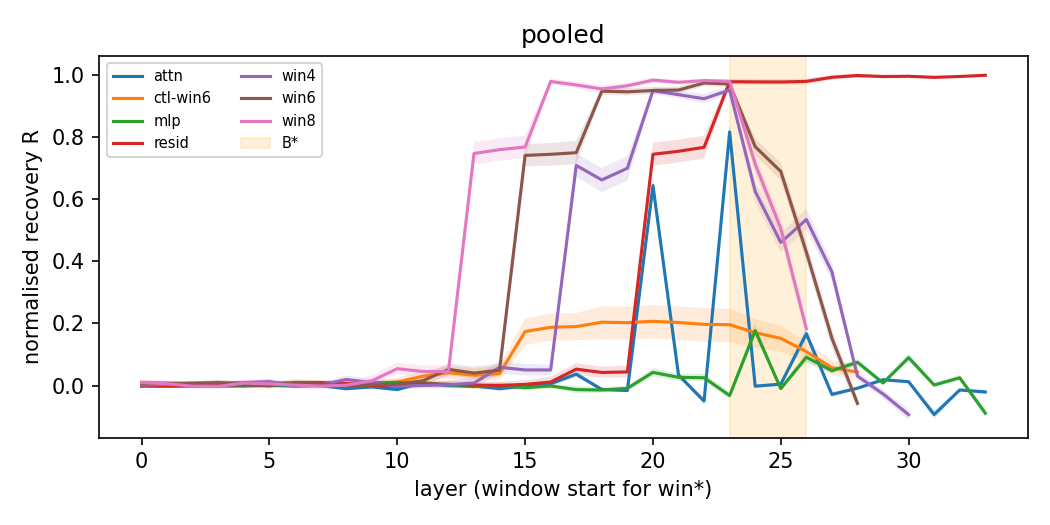

In [4]:
!python -m xling.patching --items {D}/arogyabodha.jsonl --split calib --conds {MT} --max-items 150 --exclude-sources {X}
!python -m xling.band --patch-dir {R}/medgemma/arogyabodha/calib/patching --plot
!python -m xling.patching --items {D}/arogyabodha.jsonl --split test --conds {MT} --max-items 150 --exclude-sources {X} --modes resid,attn,mlp,win4,win6,win8,ctl-win6,rev-win6
!python -m xling.band --patch-dir {R}/medgemma/arogyabodha/test/patching --plot
display(Image(f'{R}/medgemma/arogyabodha/calib/patching/recovery_pooled.png'))

## 8. Baseline B3 — training-free steering (≈ 30 min sweep on calib + ≈ 40 min test evaluation on L4)
Sweep: layers 16–26 (around the causal band), scales 1 and 2, 100 calib items per language.

In [ ]:
!python -m xling.steer --items {D}/arogyabodha.jsonl --variant mt --vectors {C}/steer_mt.npz --layers 16:28:2 --alphas 1,2 --limit 100
best = json.load(open(f'{C}/steer_sweep_mt.json'))['best']; print('best:', best)
!python -m xling.infer --items {D}/arogyabodha.jsonl --split test --conds en,{MT} --tag steer --steer-file {C}/steer_mt.npz --steer-layer {best['layer']} --steer-alpha {best['alpha']}

## 9. Phase C — adapters (≈ 1 h each on L4, 2,000 training pairs; finished adapters are skipped)
Same data and steps for every variant; B4 (all layers) gets a rank matched to the band's parameter budget.
The first run prints its speed — if it is far from ≈ 1.5–2 s per pair, stop and report it.

In [ ]:
BAND = f'{R}/medgemma/arogyabodha/calib/patching/band.json'
common = f'--items {D}/arogyabodha.jsonl --band-json {BAND} --max-pairs 2000 --seed 0'
!python -m xling.train {common} --placement band   --lam 0.5 --out {TR}/ours
!python -m xling.train {common} --placement band   --lam 0   --out {TR}/band_noalign
!python -m xling.train {common} --placement random --lam 0.5 --out {TR}/random_band
!python -m xling.train {common} --placement all    --lam 0   --match-budget --out {TR}/all_layers

## 10. Phase D — evaluate every adapter and write the report tables (≈ 40–50 min per adapter on L4)
All adapters on English + the four mt conditions; the proposed adapter also on the code-mixed conditions.

In [ ]:
for tag in ['ours', 'band_noalign', 'random_band', 'all_layers']:
    conds = 'en,' + MT + (',hi-mixed,bn-mixed,ta-mixed,te-mixed' if tag == 'ours' else '')
    !python -m xling.infer --items {D}/arogyabodha.jsonl --split test --conds {conds} --adapter {TR}/{tag} --tag {tag}
    !python -m xling.infer --items {D}/vqarad.jsonl --split test --adapter {TR}/{tag} --tag {tag}
!python -m xling.report --root {R}/medgemma/arogyabodha/test --base base --runs steer,all_layers,random_band,band_noalign,ours
!python -m xling.report --root {R}/medgemma/arogyabodha/test --base base --runs steer,all_layers,random_band,band_noalign,ours --exclude-sources {X}
!python -m xling.report --root {R}/medgemma/vqarad/test --base base --runs all_layers,random_band,band_noalign,ours

## 11. (If compute allows) Qwen2.5-VL-7B control — baseline + diagnosis

In [ ]:
MT5 = 'en,hi-mt,bn-mt,ta-mt,te-mt'
!python -m xling.infer --model qwen25vl --items {D}/arogyabodha.jsonl --split calib --conds {MT5} --capture
!python -m xling.infer --model qwen25vl --items {D}/arogyabodha.jsonl --split test  --conds {MT5} --capture
!python -m xling.diagnose --test-dir {R}/qwen25vl/arogyabodha/test/base --calib-dir {R}/qwen25vl/arogyabodha/calib/base --variant mt --plot

## Appendix — fallback translator (only if IndicTrans2 cannot be used)
NLLB-200 runs in the main environment. Use one engine for all languages.

In [ ]:
# !python -m xling.translate forward  --engine nllb --items {D}/arogyabodha.jsonl
# !python -m xling.translate backward --engine nllb --items {D}/arogyabodha.jsonl --from-variant mt --split test
# !python -m xling.translate forward  --engine nllb --items {D}/vqarad.jsonl